**Mock data manipulation for Desarrollo Profesional's mock paper** \
Antonella Zavala Cerda



In [6]:
# Import
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from google.colab import drive
drive.mount('/content/drive')
from google.colab import files

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Original mock data**

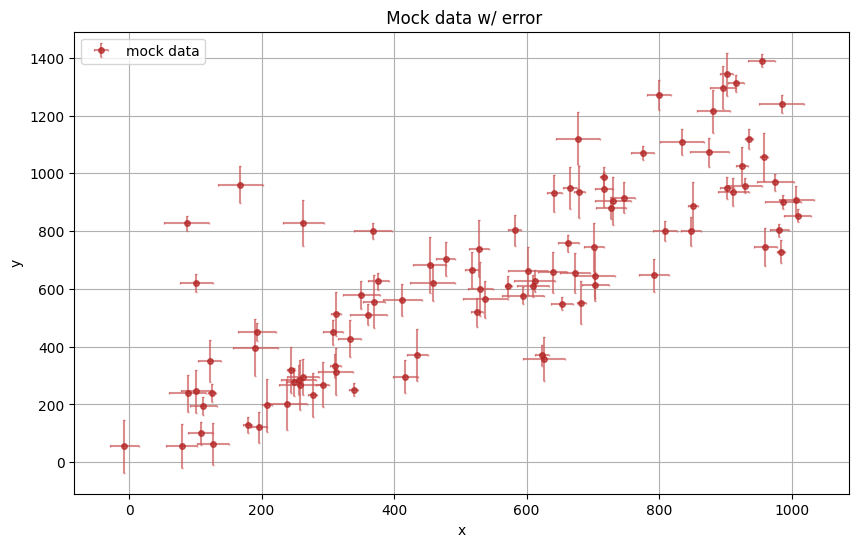

In [7]:
# Upload data
data_path = '/content/drive/MyDrive/Mock data paper/mock_data.txt'

# Read data
df = pd.read_csv(data_path, sep='\t')

# Plot w/ errorbars
plt.figure(figsize=(10, 6))
plt.errorbar(df['x'], df['y'], xerr=df['x_err'], yerr=df['y_err'],
             fmt='o', ms=4, color='firebrick', ecolor='indianred', capsize=1, label= 'mock data', alpha=0.7)

plt.title(f' Mock data w/ error')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

**Mock data manipulation**\
Pulsar phasogram (histogram shape)

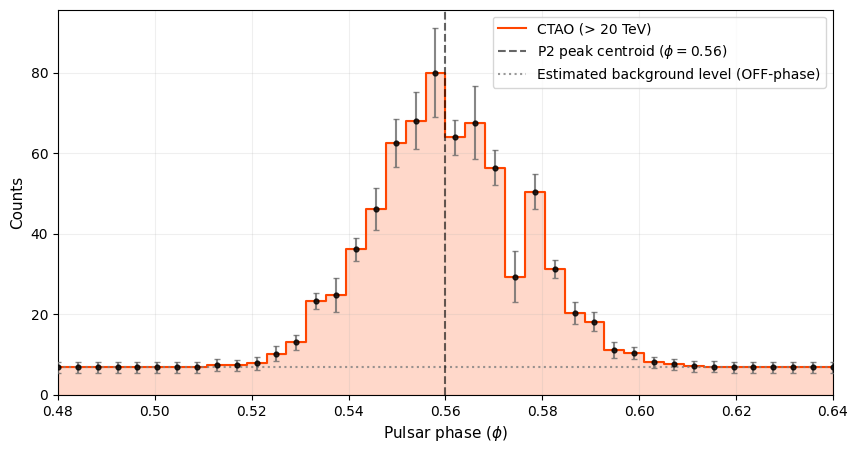

In [8]:
# Scale factor for total counts
factor_escala = 0.1

# Subsample of representative points (40)
df_phaso = df.sample(n=40, random_state=42).sort_values(by='x').reset_index(drop=True)

# X: P2 envelope phase interval [0.48 - 0.64]
df_phaso['Fase'] = np.linspace(0.48, 0.64, len(df_phaso))

# Y: CTAO signal modulation (Gaussian model, centered at 0.56, sigma: 0.015)
# centered at phase = 0.56 to be consistent with H.E.S.S observations
perfil_pulso = np.exp(-0.5 * ((df_phaso['Fase'] - 0.56) / 0.015)**2)

# Aditional constant noise (scaled)
fondo_background = (df_phaso['y'].mean() * 0.1) * factor_escala

# TeV final flux simulation + errorbar (scale factor for Y axis)
df_phaso['Flujo_TeV'] = (df_phaso['y'] * perfil_pulso * factor_escala) + fondo_background
df_phaso['Flujo_err'] = (df_phaso['y_err'] * perfil_pulso * factor_escala) + (fondo_background * 0.2)


# Phasogram plot
plt.figure(figsize=(10, 5))

# Pulse profile like a area/step (not sure of the name) plot
plt.step(df_phaso['Fase'], df_phaso['Flujo_TeV'], where='mid',
         color='orangered', linewidth=1.5, label='CTAO (> 20 TeV)')
plt.fill_between(df_phaso['Fase'], df_phaso['Flujo_TeV'], step="mid",
                 color='coral', alpha=0.3)

# Points and respective error bars
plt.errorbar(df_phaso['Fase'], df_phaso['Flujo_TeV'], yerr=df_phaso['Flujo_err'],
             fmt='.', color='black', ecolor='dimgray', capsize=2, markersize=7, alpha=0.8, zorder=3)

# Vertical line for the exact peak
plt.axvline(x=0.56, color='black', linestyle='--', alpha=0.6, zorder=4,
            label=r'P2 peak centroid ($\phi = 0.56$)')

# Estimated background level
plt.axhline(y=fondo_background, color='gray', linestyle=':', alpha=0.8,
            label='Estimated background level (OFF-phase)')

# Format and labels
plt.xlabel(r'Pulsar phase ($\phi$)', fontsize=11)
plt.ylabel(r'Counts', fontsize=11)

plt.xlim(0.48, 0.64)
plt.ylim(bottom=0)
plt.legend(loc='upper right')
plt.grid(True, linestyle='-', alpha=0.2)

plt.show()

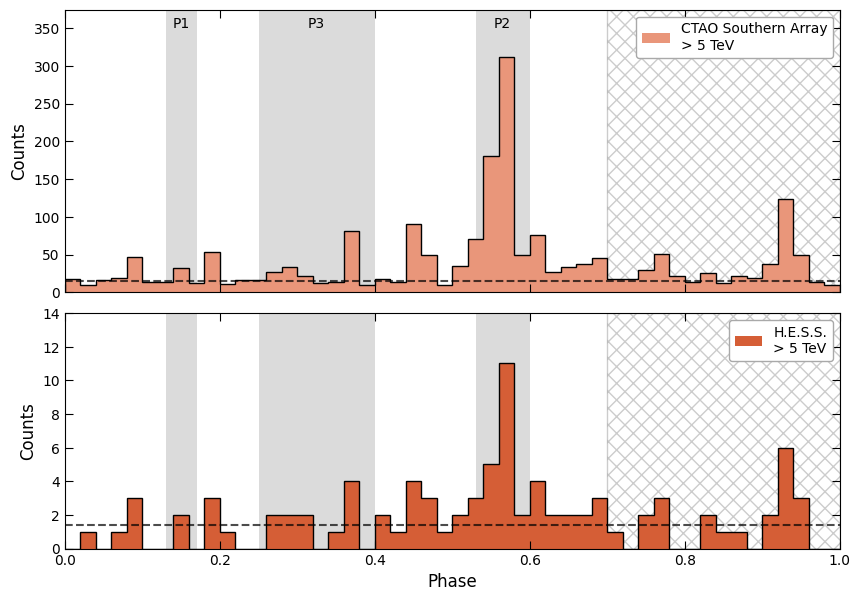

In [9]:
# Extracted data from H.E.S.S. paper
# Vela_LC.txt (appendix H.E.S.S. collaboration 2023)
from matplotlib.ticker import MaxNLocator

# H.E.S.S. data (Vela_LC.txt)
bin_edges = np.linspace(0, 1, 51) # 50 bins
hess_contents = np.array([0, 1, 0, 1, 3, 0, 0, 2, 0, 3, 1, 0, 0, 2, 2, 2, 0, 1, 4, 0, 2, 1,
                          4, 3, 1, 2, 3, 5, 11, 2, 4, 2, 2, 2, 3, 1, 0, 2, 3, 0, 0, 2, 1,
                          1, 0, 2, 6, 3, 0, 0])

# Gammapy-like simulation
#  H.E.S.S. background extraction (phase off: 0.7 a 1.0)
hess_bg = np.mean(hess_contents[35:50])

# Isolate pure signal de H.E.S.S.
hess_signal = np.maximum(0, hess_contents - hess_bg)

# IRF CTAO windows application

# Effective area factor ~25x
ctao_expected_signal = hess_signal * 25.0

# Force sharper P2 profile for CTAO data
# Inyect gaussian
fases_centros = (bin_edges[:-1] + bin_edges[1:]) / 2
perfil_p2_extra = 80 * np.exp(-0.5 * ((fases_centros - 0.56) / 0.015)**2)
ctao_expected_signal += perfil_p2_extra

# CTAO background (scaled)
ctao_bg = 15.0

# Poisson distribution - counts measured
np.random.seed(42) # Fixed seed for reproducibility
ctao_contents = np.random.poisson(ctao_expected_signal + ctao_bg)

# Phasogram construction
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 7), gridspec_kw={'height_ratios': [1.2, 1]})
plt.subplots_adjust(hspace=0)

# Shades areas
zonas = [
    (0.13, 0.17, 'lightgray', 0.8, None, 'P1'),
    (0.25, 0.40, 'lightgray', 0.8, None, 'P3'),
    (0.53, 0.60, 'lightgray', 0.8, None, 'P2'),
    (0.70, 1.00, 'none', 0.4, 'xx', 'OFF')
]

for ax in [ax1, ax2]:
    for xmin, xmax, color, alfa, trama, label in zonas:
        ax.axvspan(xmin, xmax, facecolor=color, edgecolor='gray' if trama else 'none',
                   alpha=alfa, hatch=trama, zorder=0)

        if ax == ax1 and label != 'OFF':
            ax.text((xmin+xmax)/2, ax.get_ylim()[1]*0.9 if ax.get_ylim()[1] > 1 else 350,
                    label, ha='center', fontsize=10, zorder=5)

# Upper panel - CTAO
ax1.stairs(ctao_contents, bin_edges, fill=True, color='darksalmon', label='CTAO Southern Array\n> 5 TeV')
ax1.stairs(ctao_contents, bin_edges, fill=False, color='black', linewidth=1)
ax1.axhline(y=ctao_bg, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax1.set_ylabel('Counts', fontsize=12)
ax1.set_ylim(0, max(ctao_contents) * 1.2)
ax1.legend(loc='upper right', framealpha=1, edgecolor='darkgray')
plt.subplots_adjust(hspace=0.08)

# Lower panel - H.E.S.S. (real data)
ax2.stairs(hess_contents, bin_edges, fill=True, color='#D55E36', label='H.E.S.S.\n> 5 TeV') # paper colour
ax2.stairs(hess_contents, bin_edges, fill=False, color='black', linewidth=1)
ax2.axhline(y=hess_bg, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax2.set_xlabel('Phase', fontsize=12)
ax2.set_ylabel('Counts', fontsize=12)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 14)
ax2.legend(loc='upper right', framealpha=1, edgecolor='darkgray')

# Ticks for both panels
for ax in [ax1, ax2]:
    ax.tick_params(axis='both', which='major', length=6, direction='in', top=True, right=True)
    ax.grid(False)

plt.show()

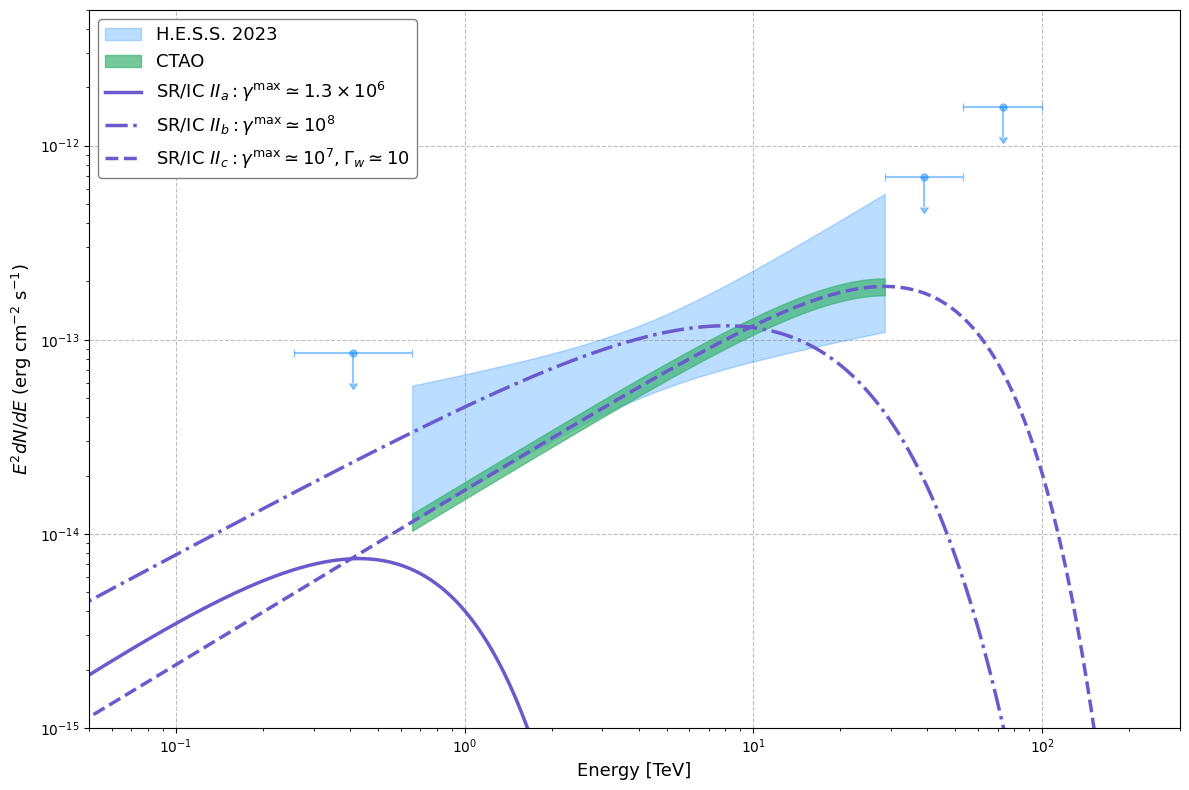

In [ ]:
# H.E.S.S data
df_box = pd.read_csv(Vela, sep=r'\s+', skiprows=3, names=['energy_GeV', 'vfv_lo', 'vfv_hi'])
df_uls = pd.read_csv(upper, sep=r'\s+', skiprows=2, names=['e_min_TeV', 'e_c_TeV', 'e_max_TeV', 'vfv'])

# TeV scales
df_box['energy_TeV'] = df_box['energy_GeV'] / 1000.0


# Theretical models
# Based on Harding et al. 2018
E_TeV = np.logspace(-2, 2.5, 300)

model_IIa = 0.8e-14 * (E_TeV / 0.2)**1.0 * np.exp(-(E_TeV / 0.5)**1.2)
model_IIb = 1.2e-13 * (E_TeV / 3.0)**0.8 * np.exp(-(E_TeV / 10.0)**1.0)
model_IIc = 2.5e-13 * (E_TeV / 20.0)**0.9 * np.exp(-(E_TeV / 40.0)**1.5)


# H.E.S.S. modification to simulate CTAO

# Ideal flux calculation for IIc model
flujo_ideal = 2.5e-13 * (df_box['energy_TeV'] / 20.0)**0.9 * np.exp(-(df_box['energy_TeV'] / 40.0)**1.5)

# Narrow error bar
# I tried to simulate an cutting-edge instrument
df_box['ctao_vfv_lo'] = flujo_ideal * 0.90
df_box['ctao_vfv_hi'] = flujo_ideal * 1.10


# Plot
plt.figure(figsize=(12, 8))

# H.E.S.S. original data
plt.fill_between(df_box['energy_TeV'], df_box['vfv_lo'], df_box['vfv_hi'],
                 color='dodgerblue', alpha=0.3, label='H.E.S.S. 2023')

# H.E.S.S. data  (upper limits)
xerr_lower = df_uls['e_c_TeV'] - df_uls['e_min_TeV']
xerr_upper = df_uls['e_max_TeV'] - df_uls['e_c_TeV']
plt.errorbar(df_uls['e_c_TeV'], df_uls['vfv'], xerr=[xerr_lower, xerr_upper],
             yerr=df_uls['vfv'] * 0.3, uplims=True, fmt='o', color='dodgerblue',
             markersize=5, capsize=3, alpha=0.5)

# Modified band (CTAO simulation)
plt.fill_between(df_box['energy_TeV'], df_box['ctao_vfv_lo'], df_box['ctao_vfv_hi'],
                 color='mediumseagreen', alpha=0.7,
                 label='CTAO ')

# SR/IC models
color_sric = 'slateblue'
plt.plot(E_TeV, model_IIa, color=color_sric, linestyle='-', linewidth=2.5,
         label=r'SR/IC $II_a : \gamma^{\max} \simeq 1.3 \times 10^6$')
plt.plot(E_TeV, model_IIb, color=color_sric, linestyle='-.', linewidth=2.5,
         label=r'SR/IC $II_b : \gamma^{\max} \simeq 10^8$')
plt.plot(E_TeV, model_IIc, color=color_sric, linestyle='--', linewidth=2.5,
         label=r'SR/IC $II_c : \gamma^{\max} \simeq 10^7, \Gamma_w \simeq 10$')

# Plot
plt.xscale('log')
plt.yscale('log')
plt.xlim(0.05, 300)
plt.ylim(1e-15, 5e-12)

plt.xlabel('Energy [TeV]', fontsize=13)
plt.ylabel(r'$E^2 dN/dE$ (erg cm$^{-2}$ s$^{-1}$)', fontsize=13)


plt.legend(loc='upper left', fontsize=13, framealpha=1, edgecolor='gray')
plt.grid(True, which="major", ls="--", alpha=0.5, color='gray')

plt.tight_layout()
plt.show()